# Lab 8


## Setup for SUSY Dataset

Use the SUSY dataset for the rest of this lab. Here is a basic setup. It reads the full file you downloaded in Lab 7 (5 million rows, about 760 MB in memory once loaded). If your computer struggles, read `../Lab.7/SUSY-small.csv` instead (the first 500,000 rows) and divide the sample sizes below by ten.

`RawNames` are the 8 quantities measured directly; `FeatureNames` are the 10 derived from them, which the physicists designed to separate signal from background. You will need both in Exercise 3.

In [29]:
# Our usual libraries...
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from IPython.display import HTML, display
import tabulate

In [30]:
filename="../Lab.7/SUSY.csv"
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", 
          "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET",
          "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=[v for v in VarNames[1:] if v not in RawNames]
df = pd.read_csv(filename, dtype='float64', names=VarNames)

## Scikit-Learn

[Scikit-learn](https://scikit-learn.org) is a rich python library for data science, including machine learning. For example, we can build a Fisher Discriminant (aka Linear Discriminant Analysis, or LDA). 

### Exercise 1: Install Scikit-Learn

`scikit-learn` is in the course `requirements.txt`, so it should already be in your environment: check that `import sklearn` works. If it doesn't, follow the [Installation Instructions](https://scikit-learn.org/stable/install.html).

In [31]:
import sklearn
print(sklearn.__version__)

1.6.1


### Exercise 2: Read About Classifiers

#### Part a
Scikit-learn offers an impressively comprehensive list of machine learning algorithms. Browse through [scikit-learn's documentation](https://scikit-learn.org/stable/index.html). You'll note the algorithms are organized into classification, regression, clustering, dimensionality reduction, model selection, and preprocessing. Browse through the list of [classification algorithms](https://scikit-learn.org/stable/supervised_learning.html#supervised-learning). 

#### Part b
Note scikit-learn's documentation is rather comprehensive. The documentation on [linear models](https://scikit-learn.org/stable/modules/linear_model.html) shows how classification problems are setup. Read about the first few methods and try to comprehend the example codes. Skim the rest of the document.

#### Part c
Read through the [LDA Documentation](https://scikit-learn.org/stable/modules/lda_qda.html).


### Exercise 3: Training a Classifier

Let's repeat what we did by hand in the previous lab (Lab 7, Exercise 8) using scikit-learn. We'll use an LDA classifier, which we can instantiate as follows:

In [32]:
import sklearn.discriminant_analysis as DA
Fisher=DA.LinearDiscriminantAnalysis()

As discussed in the lecture, to properly formulate our problem, we'll have to:

* Define the inputs (X) vs outputs (Y)
* Designate training vs testing samples (in order to get an unbiased assessment of the performance of machine learning algorithms)

For example, here we'll use 4M events for training and the remainder for testing.

In [33]:
N_Train=4000000

Train_Sample=df[:N_Train]
Test_Sample=df[N_Train:]

X_Train=Train_Sample[VarNames[1:]]
y_Train=Train_Sample["signal"]

X_Test=Test_Sample[VarNames[1:]]
y_Test=Test_Sample["signal"]

Test_sig=Test_Sample[Test_Sample.signal==1]
Test_bkg=Test_Sample[Test_Sample.signal==0]


We can train the classifier as follows:

In [34]:
Fisher.fit(X_Train,y_Train)

LinearDiscriminantAnalysis()

We can plot the output, comparing signal and background:

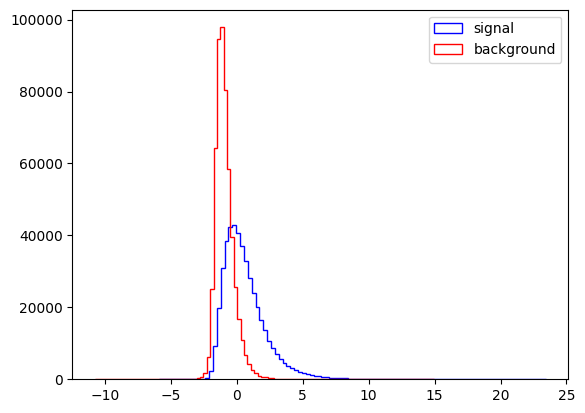

In [35]:
plt.figure()
plt.hist(Fisher.decision_function(Test_sig[VarNames[1:]]),bins=100,histtype="step", color="blue", label="signal",stacked=True)
plt.hist(Fisher.decision_function(Test_bkg[VarNames[1:]]),bins=100,histtype="step", color="red", label="background",stacked=True)
plt.legend(loc='upper right')
plt.show()

In [36]:
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning, message=".*encountered in matmul")

scores = Fisher.decision_function(X_Test)
print(np.isfinite(scores).all(), scores.min(), scores.max())

True -10.766278357388156 23.43518674403569


#### Part a

Compare the ROC curves computed on the test and on the training samples, in a single plot. Do you see a bias? (Use `Fisher.decision_function` on each sample, and `roc_curve` as in Exercise 5.)

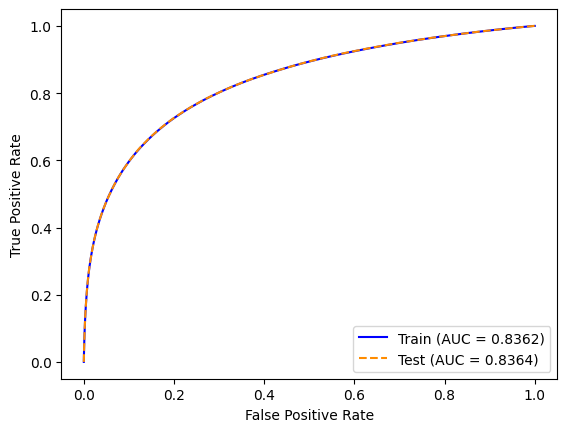

In [37]:
from sklearn.metrics import roc_curve, auc

fpr_train, tpr_train, _ = roc_curve(y_Train, Fisher.decision_function(X_Train))
fpr_test, tpr_test, _ = roc_curve(y_Test, Fisher.decision_function(X_Test))

plt.figure()
plt.plot(fpr_train, tpr_train, color='blue',
         label='Train (AUC = %0.4f)' % auc(fpr_train, tpr_train))
plt.plot(fpr_test, tpr_test, color='darkorange', linestyle='--',
         label='Test (AUC = %0.4f)' % auc(fpr_test, tpr_test))
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.show()

# there is no bias

#### Part b

Train three Fisher discriminants, using as input (1) only the raw quantities (`RawNames`), (2) only the derived features (`FeatureNames`), and (3) all 18. Compare their ROC curves, computed on the test sample, in a single plot. Which inputs carry the separation?

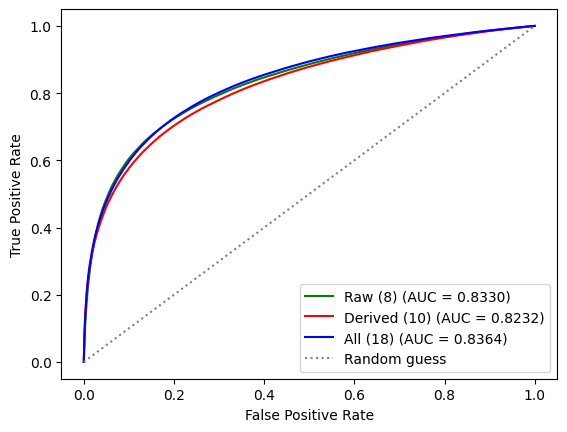

In [38]:
from sklearn.metrics import roc_curve, auc
import sklearn.discriminant_analysis as DA

input_sets = {
    "Raw (8)": RawNames,
    "Derived (10)": FeatureNames,
    "All (18)": VarNames[1:],
}
colors = ["green", "red", "blue"]

plt.figure()
for (label, cols), color in zip(input_sets.items(), colors):
    clf = DA.LinearDiscriminantAnalysis()
    clf.fit(X_Train[cols], y_Train)
    fpr, tpr, _ = roc_curve(y_Test, clf.decision_function(X_Test[cols]))
    plt.plot(fpr, tpr, color=color, label='%s (AUC = %0.4f)' % (label, auc(fpr, tpr)))

plt.plot([0, 1], [0, 1], color='gray', linestyle=':', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.show()

# the derived features have the most separation

### Exercise 4: Comparing Techniques

#### Part a
Select 3 different classifiers from the techniques listed [here](https://scikit-learn.org/stable/supervised_learning.html#supervised-learning) to compare. Note that you can use the multi-layer perceptron to build a deep network, though training may be prohibitively slow. So avoid this technique.

#### Part b

Write a function that takes an instantiated classifier and performs the comparison from Exercise 3b. Use the function on each of the classifiers you chose in part a.

#### Part c

Use the best method from part b to compute the maximal significance $\sigma_S= \frac{N_S}{\sqrt{N_S+N_B}}$ for the four scenarios in Lab 7 (Exercise 5.3), choosing the cut on the classifier's output that maximizes it.

In [39]:
# 4.a

from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

classifiers = {
    "Gradient Boosting": HistGradientBoostingClassifier(max_iter=100, random_state=0),
    "Random Forest": RandomForestClassifier(n_estimators=30, max_depth=10,
                                            n_jobs=2, random_state=0),
    "QDA": QuadraticDiscriminantAnalysis(),
}

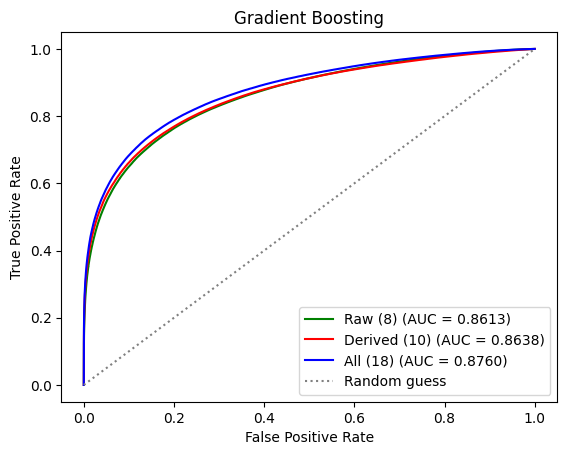

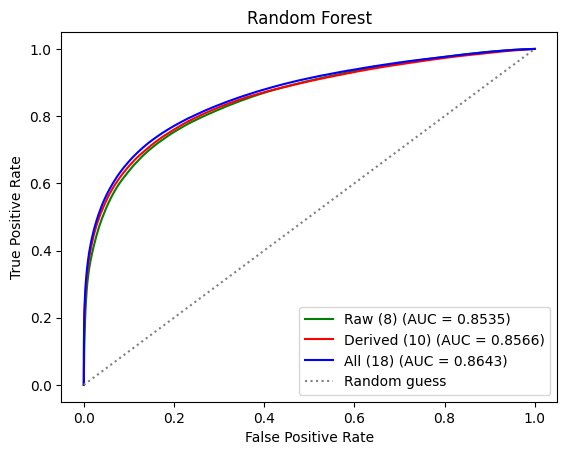

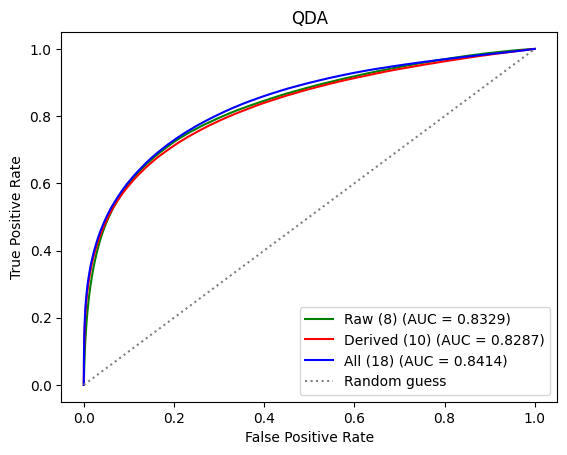

In [40]:
# 4.b

from sklearn.base import clone
from sklearn.metrics import roc_curve, auc

def get_scores(clf, X):
    """Classifier output to use for the ROC curve."""
    if hasattr(clf, "decision_function"):
        return clf.decision_function(X)
    return clf.predict_proba(X)[:, 1]

def compare_inputs(classifier, name, n_train=None):
    """Train `classifier` on raw / derived / all inputs and plot test ROC curves together.
    n_train: optionally train on only the first n_train events (to save time)."""
    input_sets = {
        "Raw (8)": RawNames,
        "Derived (10)": FeatureNames,
        "All (18)": VarNames[1:],
    }
    colors = ["green", "red", "blue"]
    X_tr, y_tr = X_Train[:n_train], y_Train[:n_train]

    plt.figure()
    aucs = {}
    for (label, cols), color in zip(input_sets.items(), colors):
        clf = clone(classifier)         
        clf.fit(X_tr[cols], y_tr)
        fpr, tpr, _ = roc_curve(y_Test, get_scores(clf, X_Test[cols]))
        aucs[label] = auc(fpr, tpr)
        plt.plot(fpr, tpr, color=color, label='%s (AUC = %0.4f)' % (label, aucs[label]))

    plt.plot([0, 1], [0, 1], color='gray', linestyle=':', label='Random guess')
    plt.title(name)
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.legend(loc='lower right')
    plt.show()
    return aucs

results = {}
for name, clf in classifiers.items():
    n = 500000 if name == "Random Forest" else None
    results[name] = compare_inputs(clf, name, n_train=n)

In [41]:
# 4.c

best_name = max(results, key=lambda n: results[n]["All (18)"])
print("Best method:", best_name)

best = clone(classifiers[best_name]).fit(X_Train, y_Train)
fpr, tpr, thresholds = roc_curve(y_Test, get_scores(best, X_Test))

scenarios = [
    (10, 100),
    (100, 1000),
    (1000, 10000),
    (10000, 100000),
]

def significance(eff_s, eff_b, N_S, N_B):
    N_S_prime = eff_s * N_S
    N_B_prime = eff_b * N_B
    denominator = np.sqrt(N_S_prime + N_B_prime)
    return np.divide(N_S_prime, denominator,
                     out=np.zeros_like(N_S_prime, dtype=float),
                     where=denominator > 0)

rows = []
for N_S, N_B in scenarios:
    sigma = significance(tpr, fpr, N_S, N_B)
    i = np.argmax(sigma)
    rows.append({"N_S": N_S, "N_B": N_B, "Best cut": thresholds[i],
                 "epsilon_S (TPR)": tpr[i], "epsilon_B (FPR)": fpr[i],
                 "N'_S": tpr[i] * N_S, "N'_B": fpr[i] * N_B,
                 "Max significance": sigma[i]})

sig_table = pd.DataFrame(rows)
display(sig_table.round(4))

Best method: Gradient Boosting


,N_S,N_B,Best cut,epsilon_S (TPR),epsilon_B (FPR),N'_S,N'_B,Max significance
0,10,100,1.5245,0.4785,0.021,4.7854,2.0992,1.8238
1,100,1000,1.5245,0.4785,0.021,47.8545,20.9924,5.7674
2,1000,10000,1.5245,0.4785,0.021,478.5448,209.9242,18.2381
3,10000,100000,1.5245,0.4785,0.021,4785.4476,2099.2419,57.6740


### Exercise 5: Metrics

Scikit-learn provides methods for computing the FPR, TPR, ROC, AUC metrics. For example:

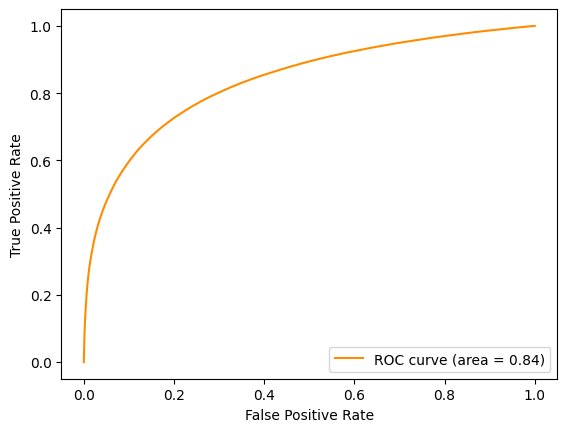

In [42]:
from sklearn.metrics import roc_curve, auc
fpr, tpr, _ = roc_curve(y_Test, Fisher.decision_function(X_Test))

roc_auc = auc(fpr, tpr)

plt.plot(fpr,tpr,color='darkorange',label='ROC curve (area = %0.2f)' % roc_auc)
plt.legend(loc="lower right")
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.show()


#### Part a
TPR/FPR/ROC/AUC are one way of assessing the quality of a classifier. Read about [Precision and Recall](https://en.wikipedia.org/wiki/Precision_and_recall), [Accuracy](https://en.wikipedia.org/wiki/Accuracy_and_precision), and [F-score](https://en.wikipedia.org/wiki/F-score).

#### Part b
Look through [model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html#) documentation. Using scikit-learn's tools, compute TPR, FPR, ROC, AUC, Precision, Recall, F1 score, and accuracy for the method you selected in Exercise 4c and each scenario. Make a nice table, which also includes the maximal significance. 


In [43]:
# 5.b

from sklearn.metrics import (roc_curve, auc, confusion_matrix,
                             precision_score, recall_score, f1_score, accuracy_score)

scores = get_scores(best, X_Test)
y_true = np.asarray(y_Test)
n_sig, n_bkg = (y_true == 1).sum(), (y_true == 0).sum()

rows = {}
for (N_S, N_B), (_, r) in zip(scenarios, sig_table.iterrows()):
    w = np.where(y_true == 1, N_S / n_sig, N_B / n_bkg)

    cut = r["Best cut"]
    y_pred = (scores >= cut).astype(int)          

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, sample_weight=w).ravel()
    fpr_w, tpr_w, _ = roc_curve(y_true, scores, sample_weight=w)

    rows[f"N_S={N_S}, N_B={N_B}"] = {
        "Cut on classifier output": cut,
        "TPR": tp / (tp + fn),
        "FPR": fp / (fp + tn),
        "AUC": auc(fpr_w, tpr_w),
        "Precision": precision_score(y_true, y_pred, sample_weight=w),
        "Recall": recall_score(y_true, y_pred, sample_weight=w),
        "F1 score": f1_score(y_true, y_pred, sample_weight=w),
        "Accuracy": accuracy_score(y_true, y_pred, sample_weight=w),
        "Max significance": r["Max significance"],
    }

metrics_table = pd.DataFrame(rows)
display(metrics_table.round(4))

,"N_S=10, N_B=100","N_S=100, N_B=1000","N_S=1000, N_B=10000","N_S=10000, N_B=100000"
Cut on classifier output,1.5245,1.5245,1.5245,1.5245
TPR,0.4785,0.4785,0.4785,0.4785
FPR,0.0210,0.0210,0.0210,0.0210
AUC,0.8760,0.8760,0.8760,0.8760
Precision,0.6951,0.6951,0.6951,0.6951
Recall,0.4785,0.4785,0.4785,0.4785
F1 score,0.5668,0.5668,0.5668,0.5668
Accuracy,0.9335,0.9335,0.9335,0.9335
Max significance,1.8238,5.7674,18.2381,57.6740


In [44]:
print("hi")

hi
